# 03 · LIF Conv2D: convolutional layers

In [02 · Connectivity](./02_connectivity.ipynb) you listed every synapse by hand, one line each.

Images make that impractical. The layer below runs a 3×3 filter over a 16×16 image. It needs 1,764
synapses, but only 9 different weights, reused at every position.

On SpiNNaker2 that is the **`lif_conv2d`** neuron model with
[`snn.Conv2DProjection`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/snn-api.html),
which generates the per-position synapses from the filter and its geometry.

New to convolutions? The
[Convolutional neural network](https://en.wikipedia.org/wiki/Convolutional_neural_network) article
covers the background.

**By the end you'll be able to:**

- encode an image as spikes and feed it to a convolutional layer
- configure a `Conv2DProjection` — kernel, stride, padding, pooling — and work out its output shape
- lay a multi-channel feature map across cores with `set_max_atoms_per_core`
- read feature maps back and tell what each channel responded to


## 1. Setup

NumPy to build the image, matplotlib to look at the result, and the usual py-spinnaker2 imports.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from spinnaker2 import brian2_sim, helpers, snn

Like every notebook in this series, this one runs on the **Brian2 software backend** by
default, so you can follow along without a board. `lif_conv2d` is supported by both backends, so
the network below runs unchanged on real hardware once you flip the switch.


In [2]:
# Flip this to True once you have a SpiNNaker2 board configured.
USE_HARDWARE = True

if USE_HARDWARE:
    from spinnaker2 import hardware

    hw = hardware.SpiNNcloud48NodeBoard()  # or hardware.SpiNNaker2Chip()
else:
    hw = brian2_sim.Brian2Backend()

print("Running on backend:", type(hw).__name__)

INFO:     Path to spinnaker configuration directory found in global config path /etc/opt/spinnaker/SPINNAKER_CONFIG_PATH


Running on backend: SpiNNcloud48NodeBoard


## 2. The input: an image as spikes

The input is a 16×16 image with a bright 6×6 square in the middle. Each **bright** pixel becomes a
spike source that fires on every timestep from `t=0` to `t=9`; dark pixels never fire.

The 256 pixels are flattened row-major into a `spike_list` population — the same spike source you
met in [01 · Core concepts](./01_core_concepts.ipynb). Position matters here: the convolution
reads index `i` as row `i // 16`, column `i % 16`.


In [3]:
input_image = np.zeros((16, 16), dtype=np.uint8)
input_image[5:11, 5:11] = 1  # bright 6x6 square, rows/cols 5..10

# every bright pixel spikes on t=0..9; dark pixels stay silent
input_spikes = {
    row * 16 + col: (list(range(10)) if input_image[row, col] else []) for row in range(16) for col in range(16)
}
stim = snn.Population(size=256, neuron_model="spike_list", params=input_spikes, name="stim")

print(f"bright pixels: {input_image.sum()} of {input_image.size}")
print(f"spikes per bright pixel: {len(input_spikes[5 * 16 + 5])}")

bright pixels: 36 of 256
spikes per bright pixel: 10


Worth a look before we go further — everything below is about what a filter makes of *this*:


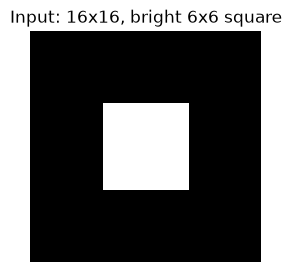

In [4]:
fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(input_image, cmap="gray")
ax.set_title("Input: 16x16, bright 6x6 square")
ax.axis("off")
plt.show()

## 3. Sizing the layer

A convolution is defined by its geometry, and the geometry fixes how many neurons you need. With a
**3×3 kernel**, **stride 1** and **no padding**, each spatial dimension shrinks by two:

```
out = (in - kernel) / stride + 1 = (16 - 3) / 1 + 1 = 14
```

So one feature map is 14×14. We want **two** of them — two different filters over the same input —
which makes `2 × 14 × 14 = 392` output neurons in total.

`conv_params` carries that geometry. `pool_*` would down-sample the output further; `1` means no
pooling.


In [5]:
conv_params = {
    "in_height": 16,
    "in_width": 16,
    "stride_x": 1,
    "stride_y": 1,
    "pool_x": 1,
    "pool_y": 1,
    "pad_top": 0,
    "pad_bottom": 0,
    "pad_left": 0,
    "pad_right": 0,
}

kernel_size = 3
out_channels = 2
output_height = (16 - kernel_size) // conv_params["stride_y"] + 1
output_width = (16 - kernel_size) // conv_params["stride_x"] + 1
output_size = out_channels * output_height * output_width

print(f"feature map: {output_height}x{output_width} per channel")
print(f"{out_channels} channels -> {output_size} output neurons")

feature map: 14x14 per channel
2 channels -> 392 output neurons


## 4. The filters

The weight tensor is shaped `(in_channels, out_channels, kernel_height, kernel_width)`. One input
channel (greyscale), two output channels, each a 3×3 filter. The two are deliberately easy to read:

- **Channel 0 — brightness detector.** Every weight is `2`, so it responds to *how much* of its
  3×3 window is bright.
- **Channel 1 — centre detector.** Only the middle weight is non-zero (`8`); it ignores the edges
  of its window entirely and reports on a single pixel.


In [6]:
weights = np.zeros((1, out_channels, kernel_size, kernel_size), dtype=np.int8)
weights[0, 0, :, :] = 2  # channel 0: brightness - every pixel in the window counts
weights[0, 1, 1, 1] = 8  # channel 1: centre - only the middle pixel counts

print("channel 0 (brightness):", weights[0, 0].tolist())
print("channel 1 (centre):    ", weights[0, 1].tolist())

channel 0 (brightness): [[2, 2, 2], [2, 2, 2], [2, 2, 2]]
channel 1 (centre):     [[0, 0, 0], [0, 8, 0], [0, 0, 0]]


**What one neuron sees.** Take the neuron at row 5, column 5 of channel 0. Its 3×3 window
covers input rows 5–7 and columns 5–7 — entirely inside the bright square. All nine pixels spike on
every timestep from 0 to 9, and each contributes its weight of 2, so this neuron receives

```
9 pixels x weight 2 = 18 units of charge per timestep, for 10 timesteps = 180 total
```

A neuron near the edge of the square sees only part of it, gets less charge, and fires less often.
That gradient is the whole result.


## 5. The neurons

`lif_conv2d` neurons behave like the LIF neurons from
[01 · Core concepts](./01_core_concepts.ipynb); only their wiring is special. Two parameter choices
here make the output easy to reason about:

- **`alpha_decay = 1.0` — no leak.** Charge that arrives is never lost, so the membrane voltage
  accumulates everything the neuron's window has seen.
- **`reset = "reset_by_subtraction"`.** Firing removes exactly `threshold` from the membrane
  instead of clearing it, so surplus charge is carried over rather than discarded.

With `threshold = 5.0`, and knowing a neuron can emit **at most one spike per timestep**, we can
predict the run before we make it. The peak neuron banks 180 units of charge, and each spike gives
back 5. It keeps firing while the membrane is *above* the threshold — not merely at it — so it
fires 35 times, once per timestep, and ends holding the last 5. That firing continues well after
the input stops at `t=9`. The centre-channel neuron under the same spot banks `8 × 10 = 80` and
fires 15 times by the same argument.

Section 8 reads both of those neurons back, so we can check these predicted spike counts against
what the run actually produced.


In [7]:
neuron_params = {
    "threshold": 5.0,
    "alpha_decay": 1.0,  # 1.0 = no leak, the neuron just accumulates
    "i_offset": 0.0,
    "v_reset": 0.0,
    "reset": "reset_by_subtraction",
}

## 6. Building the network

Now the pieces come together. Three details matter here:

- **The population size follows from the feature map**, it is not a free choice: you need one
  neuron per output position per channel, `out_channels × out_height × out_width`, which is
  `2 × 14 × 14 = 392` here.
- **A feature map must fit on one core.** That is what `set_max_atoms_per_core(196)` is for —
  196 is `14 × 14`, exactly one channel. This is not a tuning parameter: if a feature map ends up
  split across cores, the convolution does **not** compute the right result. See
  [04 · Hardware allocation](./04_hardware_allocation.ipynb) for what `set_max_atoms_per_core()` controls in
  general.
- **`snn.Conv2DProjection` replaces the connection list.** In
  [02 · Connectivity](./02_connectivity.ipynb) a projection is an explicit list of
  `(pre, post, weight, delay)` synapses. Here you pass the kernel and the geometry instead, and the
  synapses for every window position are generated for you, all sharing the same nine weights.


In [8]:
conv_pop = snn.Population(
    size=output_size,
    neuron_model="lif_conv2d",
    params=neuron_params,
    name="conv_pop",
    record=["spikes", "v"],
)
conv_pop.set_max_atoms_per_core(output_height * output_width)  # one channel per core

conv_proj = snn.Conv2DProjection(stim, conv_pop, weights=weights, params=conv_params)

net = snn.Network("conv2d network")
net.add(stim, conv_pop, conv_proj)

## 7. Run it

Nothing convolution-specific — 50 timesteps on whichever backend you picked in section 1. We run
well past the input window so we can watch the neurons discharge.


In [9]:
timesteps = 50
hw.run(net, timesteps)

Number of cores needed: 3
Number of available cores: 7104
Sim duration: 0.060000000000000005 s


Recording post-processing duration: 0 s


## 8. Reading the feature maps

`get_spikes()` returns a dict with **one entry per neuron**, empty list included — which matters
when counting how many were actually active.

The neuron ids are flat, so to get pictures back we reshape them into
`(channel, row, column)` — the same layout the projection assumed.


In [10]:
spike_times = conv_pop.get_spikes()

spike_counts = np.zeros(output_size)
for neuron_id, spikes in spike_times.items():
    spike_counts[neuron_id] = len(spikes)
feature_maps = spike_counts.reshape((out_channels, output_height, output_width))

# the two neurons we made predictions about in section 5
print("channel 0, row 5, col 5 ->", len(spike_times[0 * 196 + 5 * 14 + 5]), "spikes")
print("channel 1, row 5, col 5 ->", len(spike_times[1 * 196 + 5 * 14 + 5]), "spikes")

active = sum(1 for s in spike_times.values() if s)
print(f"\nneurons that fired: {active} of {output_size}")
print(
    f"total spikes: {int(spike_counts.sum())}"
    f"  (channel 0: {int(feature_maps[0].sum())}, channel 1: {int(feature_maps[1].sum())})"
)

channel 0, row 5, col 5 -> 36 spikes
channel 1, row 5, col 5 -> 16 spikes

neurons that fired: 100 of 392
total spikes: 1872  (channel 0: 1296, channel 1: 576)


The raster shows *when* every output neuron fired. Below it, the input sits next to the two feature
maps, which show *how often* each neuron fired, laid back out in space.


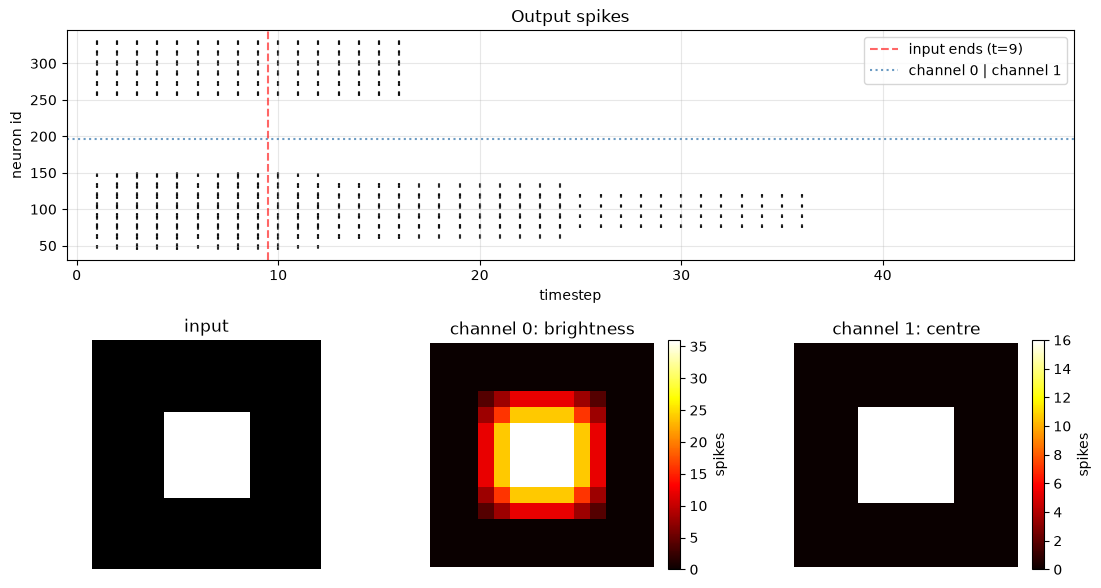

In [11]:
fig = plt.figure(figsize=(13, 7))
gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.3)

ax = fig.add_subplot(gs[0, :])
indices, times = helpers.spike_times_dict_to_arrays(spike_times)
ax.scatter(times, indices, s=3, alpha=0.6, color="black", marker="|")
ax.axvline(9.5, color="red", linestyle="--", alpha=0.6, label="input ends (t=9)")
ax.axhline(196, color="steelblue", linestyle=":", alpha=0.8, label="channel 0 | channel 1")
ax.set(title="Output spikes", xlabel="timestep", ylabel="neuron id", xlim=(-0.5, timesteps - 0.5))
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)

# the input next to the maps, so the two channels can be compared against what produced them
ax = fig.add_subplot(gs[1, 0])
ax.imshow(input_image, cmap="gray")
ax.set_title("input")
ax.axis("off")

for col, (channel, name) in enumerate([(0, "channel 0: brightness"), (1, "channel 1: centre")], start=1):
    ax = fig.add_subplot(gs[1, col])
    im = ax.imshow(feature_maps[channel], cmap="hot")
    ax.set_title(name)
    ax.axis("off")
    plt.colorbar(im, ax=ax, label="spikes")

plt.show()

**What to notice:**

- **The predictions hold.** **35** spikes on the brightness channel and **15** on the centre
  channel, exactly as worked out in section 5. Both neurons finish the run holding `v = 5.0` — the
  last threshold's worth of charge, which never crosses and so is never spent.

- **The two channels see different things.** Brightness gives a graded 8×8 blob — 64 neurons,
  from 3 spikes at the corners to 35 in the middle, because windows near the square's edge only
  partly overlap it. The centre detector gives a crisp 6×6 block of 36 neurons all firing 15
  times: it tracks one pixel, so it reproduces the square exactly.

- **Firing outlasts the input.** Spikes run to `t=35` though input stops at `t=9` (dashed line).
  One spike per timestep is the ceiling, so a neuron holding 180 units needs 36 timesteps to give
  them back. This is what `alpha_decay = 1.0` buys you — and what a decay below 1.0 would shorten,
  by letting charge leak away instead of turning into late spikes.

- **Only 100 of the 392 neurons fired.** The other 292 stayed at `v = 0` for the whole run:
  their windows contain no bright pixels, so they never receive any charge. Since the population was
  created with `record=["spikes", "v"]`, you can confirm that with `conv_pop.get_voltages()`.


## Recap & what's next

- `lif_conv2d` + `Conv2DProjection` express a convolution as a **shared** kernel instead of an
  enumerated synapse list.
- Output shape follows from the geometry: `(in - kernel) / stride + 1` per spatial dimension,
  times the number of output channels.
- The weight tensor is `(in_channels, out_channels, kernel_height, kernel_width)`.
- `set_max_atoms_per_core` decides how the feature map is split across cores.
- A feature map is offset relative to the input, because each neuron reports on the *centre* of
  its receptive field.

---

**Next up — [04 · Hardware allocation](./04_hardware_allocation.ipynb):** moving from the
simulator to real boards — choosing a specific SpiNNaker2 board to run on.
